In [1]:
#lookin at filtered snrs

In [15]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp
import corner
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [3]:
concat2 = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_filtered2')

In [13]:
concat2['global_noise_over_average']=concat2['noise_global_brightening']/concat2['local_average_outside_brightening']

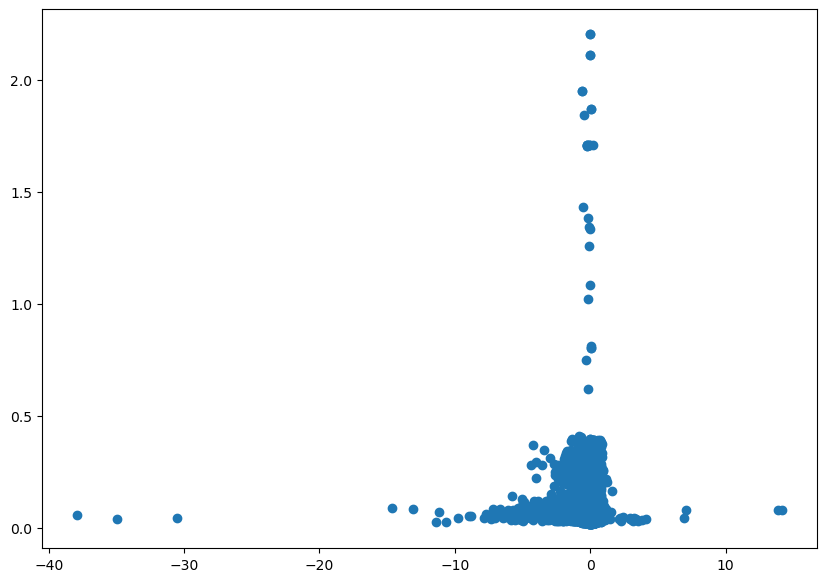

In [16]:
plt.scatter(concat2['snr_local_brightening_filtered2']-concat2['snr_local_brightening'], concat2['global_noise_over_average'])

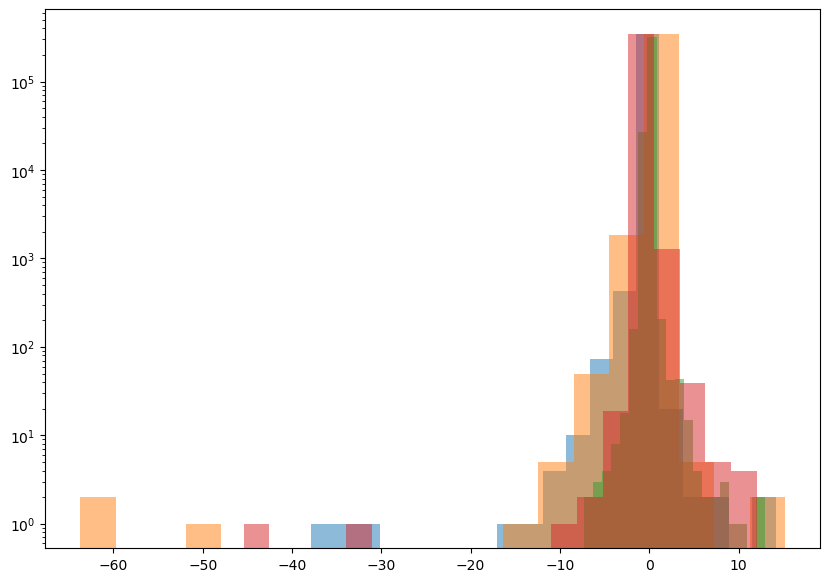

In [8]:
plt.hist(concat2['snr_local_brightening_filtered2']-concat2['snr_local_brightening'], bins=20, alpha=.5)
plt.hist(concat2['snr_global_brightening_filtered2']-concat2['snr_global_brightening'], bins=20,alpha=.5)
plt.hist(concat2['snr_local_dimming_filtered2']-concat2['snr_local_dimming'], bins=20, alpha=.5)
plt.hist(concat2['snr_global_dimming_filtered2']-concat2['snr_global_dimming'], bins=20,alpha=.5)

plt.yscale('log')

In [23]:
final_df.iloc[0]

Unnamed: 0.4                                                           254690
Unnamed: 0.3                                                           254690
Unnamed: 0.2                                                           254690
Unnamed: 0.1                                                               24
Unnamed: 0                                                                 15
filename                             ztf_20221020157697_000640_zi_c01_x_0021.
quad                                                                        2
type                                                                      pos
row_from_nn                                                               0.0
col_from_nn                                                            2504.0
detection_size                                                              5
closest_x                                                              2515.0
closest_y                                                       

In [36]:
def make_bestlist(local_or_global="local", num=100):
    df = concat.copy()
    df["concat_index_copy"] = concat.index.values
    beginningstodrop = []
    for index in df.index.values:
        if df.loc[index, 'filename'][-5:]=='0000.':
            if df.loc[index,'quad']==1 or concat.loc[index,'quad']==2:
                if df.loc[index, 'row_from_nn']<90:
                    beginningstodrop.append(index)
            elif df.loc[index,'quad']==3 or concat.loc[index,'quad']==4:
                if df.loc[index, 'row_from_nn']>2970:
                    beginningstodrop.append(index)
                
    droplist = np.unique(np.hstack((np.array(final_satlist), brightening[brightening['sobel_ratiocentral_point_brightening5']<=2]['index_copy'].values)))

    badlcs = concat[concat['global_noise_over_average']>.16].index.values
    df.drop(index=np.unique(np.hstack((droplist,badlcs, beginningstodrop))), inplace=True)
    indices_to_remove = []
    bad_lcs_from_inspection_df = concat.loc[bad_lcs_from_inspection]
    for i, row in bad_lcs_from_inspection_df.iterrows():
        for concat_i, concat_row in df.sort_values('snr_'+local_or_global+'_brightening', ascending=False)[:300].iterrows():
            if (concat_row['filename']==row['filename']) * (concat_row['quad']==row['quad']) * (concat_row['closest_x']==row['closest_x']):
                indices_to_remove.append(concat_i)
        for concat_i, concat_row in df.sort_values('snr_'+local_or_global+'_dimming', ascending=False)[:300].iterrows():
            if (concat_row['filename']==row['filename']) * (concat_row['quad']==row['quad']) * (concat_row['closest_x']==row['closest_x']):
                indices_to_remove.append(concat_i)
    df.drop(index=indices_to_remove, inplace=True)
    dfs_pos = df.sort_values("snr_"+local_or_global+"_brightening", ascending=False)[:num]
    dfs_neg = df.sort_values("snr_"+local_or_global+"_dimming", ascending=False)[:num]
    dfs_pos['snr'] = dfs_pos["snr_"+local_or_global+"_brightening"]
    dfs_pos['real_type'] = np.full(num, "pos")
    dfs_neg['snr'] = dfs_neg["snr_"+local_or_global+"_dimming"]
    dfs_neg['real_type'] = np.full(num, "neg")
    all_df = pd.concat([dfs_pos,dfs_neg])
    final_df = all_df.sort_values("snr", ascending=False)[:num]
    print("using num pos: "+str(np.sum(final_df['real_type']=="pos")))
    return final_df, dfs_pos, dfs_neg

In [43]:
def make_bestlist_filt(olddf, local_or_global="local", num=100, filt='_filtered2'):
    # filt = '_filtered2'
    df = olddf.copy()
    df["concat_index_copy"] = olddf.index.values
    beginningstodrop = []
    for index in df.index.values:
        if df.loc[index, 'filename'][-5:]=='0000.':
            if df.loc[index,'quad']==1 or olddf.loc[index,'quad']==2:
                if df.loc[index, 'row_from_nn']<90:
                    beginningstodrop.append(index)
            elif df.loc[index,'quad']==3 or olddf.loc[index,'quad']==4:
                if df.loc[index, 'row_from_nn']>2970:
                    beginningstodrop.append(index)
                
    droplist=np.load('/home/3155/droplist_partial.npy')
    badlcs = olddf[olddf['global_noise_over_average']>.16].index.values
    df.drop(index=np.unique(np.hstack((droplist,badlcs, beginningstodrop))), inplace=True)
    indices_to_remove = []
    # bad_lcs_from_inspection = np.load('/home/3155/bad_lcs_from_inspection.npy')
    # bad_lcs_from_inspection_df = olddf.loc[bad_lcs_from_inspection]
    # for i, row in bad_lcs_from_inspection_df.iterrows():
    #     for concat_i, concat_row in df.sort_values('snr_'+local_or_global+'_brightening'+filt, ascending=False)[:300].iterrows():
    #         if (concat_row['filename']==row['filename']) * (concat_row['quad']==row['quad']) * (concat_row['closest_x']==row['closest_x']):
    #             indices_to_remove.append(concat_i)
    #     for concat_i, concat_row in df.sort_values('snr_'+local_or_global+'_dimming'+filt, ascending=False)[:300].iterrows():
    #         if (concat_row['filename']==row['filename']) * (concat_row['quad']==row['quad']) * (concat_row['closest_x']==row['closest_x']):
    #             indices_to_remove.append(concat_i)
    # df.drop(index=indices_to_remove, inplace=True)
    dfs_pos = df.sort_values("snr_"+local_or_global+"_brightening"+filt, ascending=False)[:num]
    dfs_neg = df.sort_values("snr_"+local_or_global+"_dimming"+filt, ascending=False)[:num]
    dfs_pos['snr'+filt] = dfs_pos["snr_"+local_or_global+"_brightening"+filt]
    dfs_pos['real_type'+filt] = np.full(num, "pos")
    dfs_neg['snr'+filt] = dfs_neg["snr_"+local_or_global+"_dimming"]
    dfs_neg['real_type'+filt] = np.full(num, "neg")
    all_df = pd.concat([dfs_pos,dfs_neg])
    final_df = all_df.sort_values("snr"+filt, ascending=False)[:num]
    print("using num pos: "+str(np.sum(final_df['real_type'+filt]=="pos")))
    return final_df, dfs_pos, dfs_neg

In [38]:
concat = concat2

In [44]:
final_df_nofilt, dfs_pos, dfs_neg = make_bestlist_filt(concat2, filt='')

using num pos: 13


In [46]:
final_df, dfs_pos, dfs_neg = make_bestlist_filt(concat2)

using num pos: 52


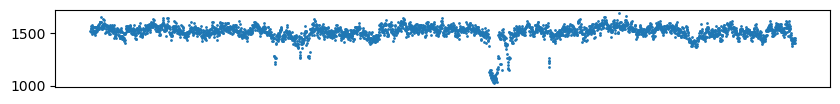

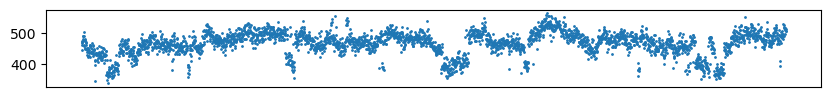

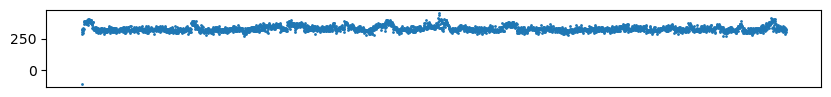

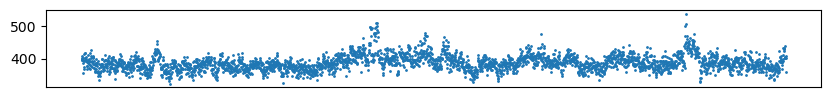

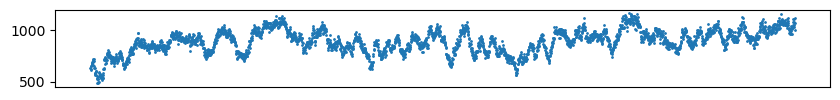

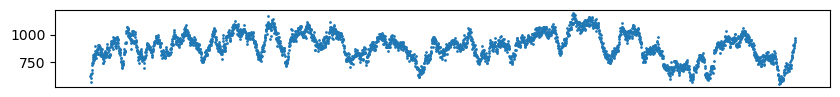

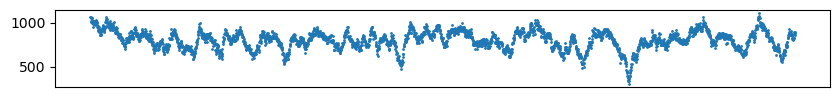

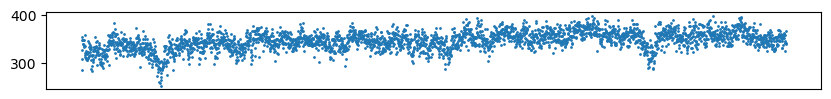

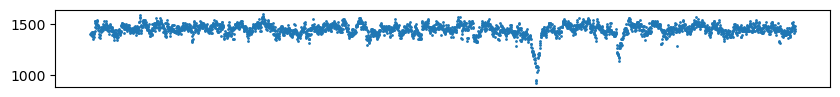

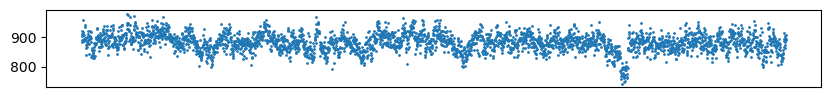

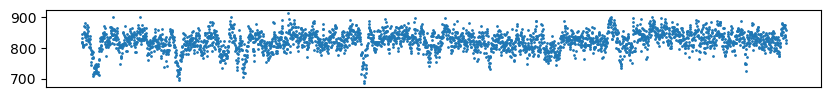

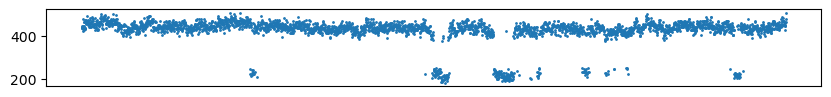

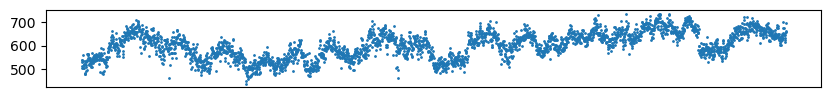

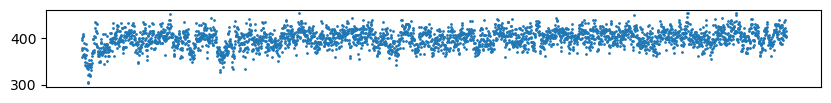

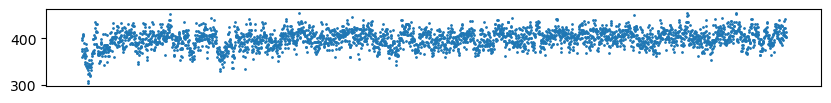

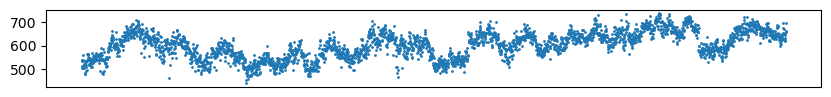

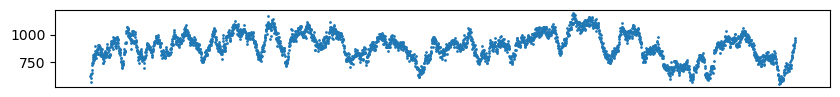

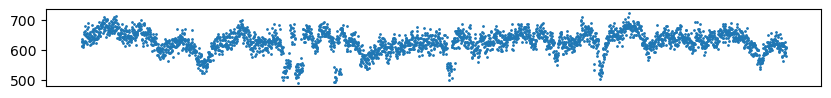

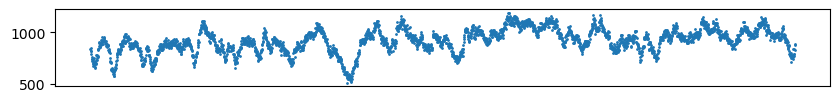

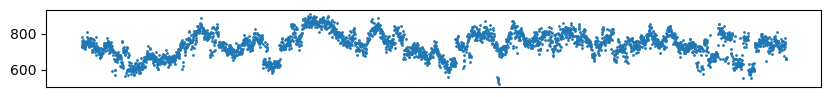

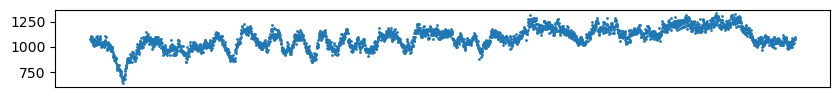

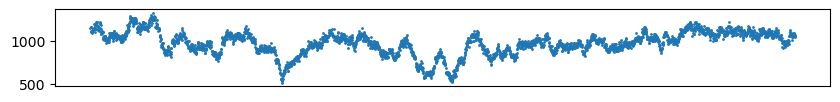

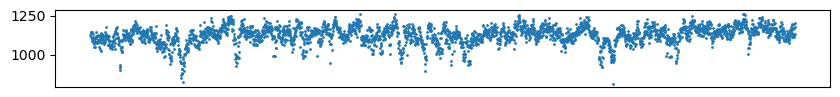

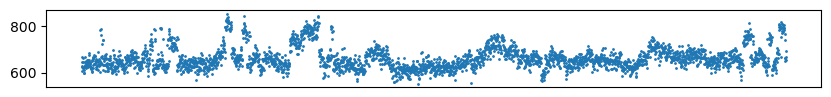

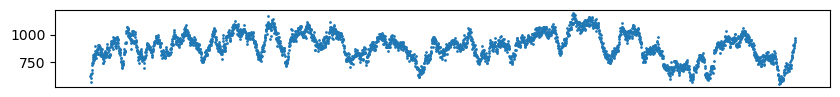

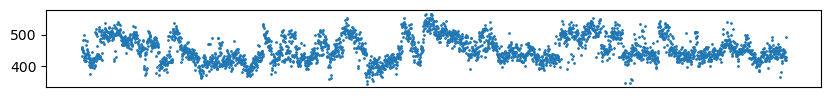

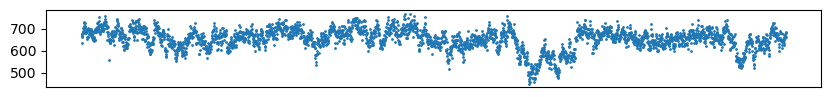

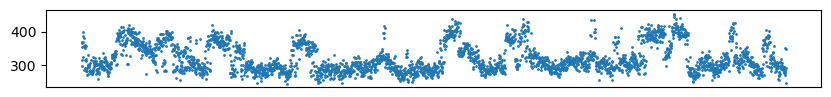

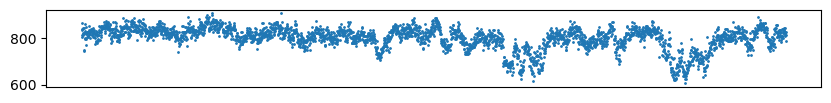

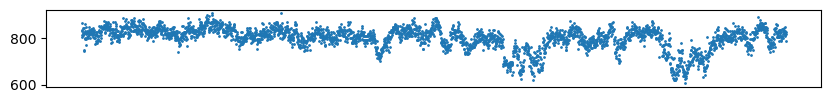

In [45]:
plt.rcParams["figure.figsize"] = (10, 1)

# final_df=concat2.sort_values('snr_local_brightening_filtered2', ascending=False).drop(index=droplist)[:20]
for index in final_df_nofilt.index[:30].values:
    # print(concat.loc[index,'global_noise_over_average'])
    # plt.set_figsize((5,2))
    tot, maxols = rff.get_tot_csv(concat2, index)
    plt.plot(tot, '.', ms=2)
    # plt.title(str(final_df.loc[index, "real_type"])+", "+str(final_df.loc[index, "concat_index_copy"]))
    plt.xticks([])
    # plt.xlim(newbrightening.loc[index, 'central_point_brightening']-15, newbrightening.loc[index, 'central_point_brightening']+15)
    plt.show()

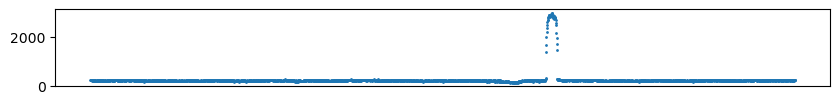

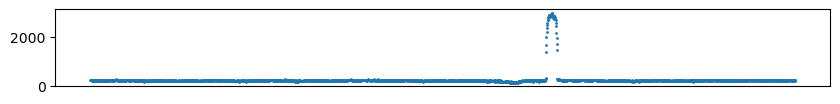

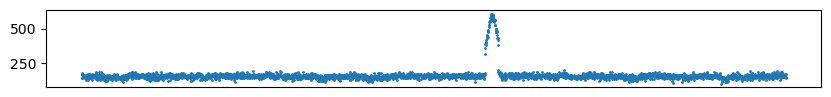

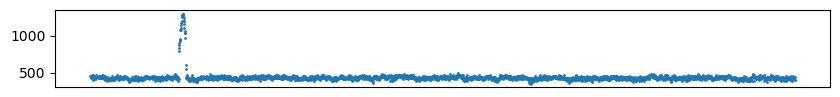

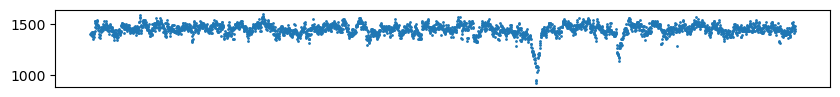

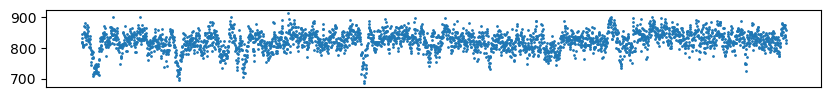

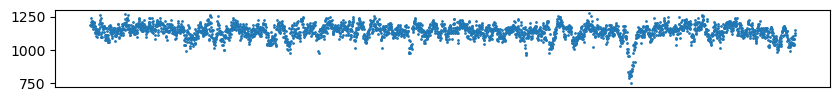

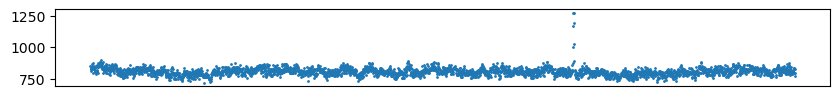

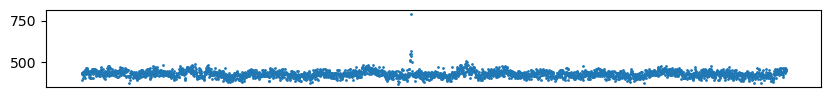

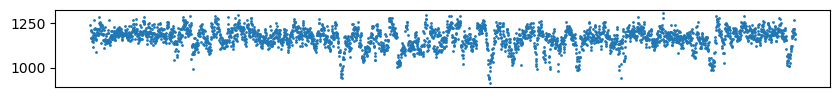

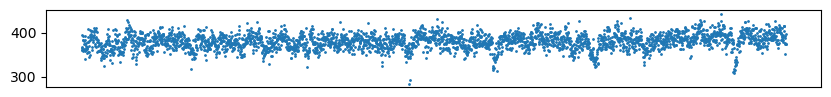

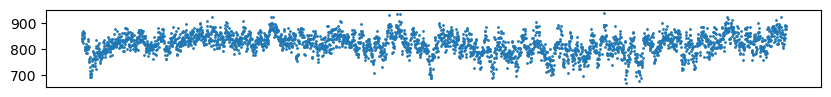

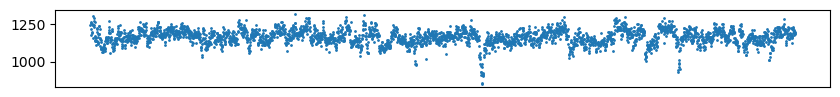

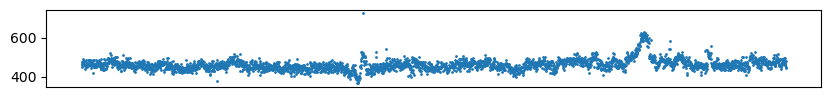

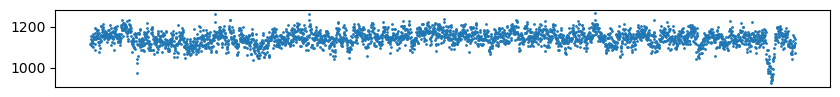

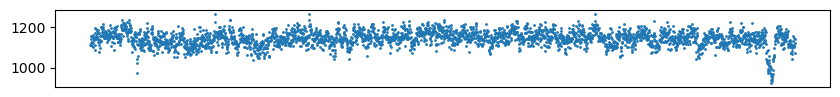

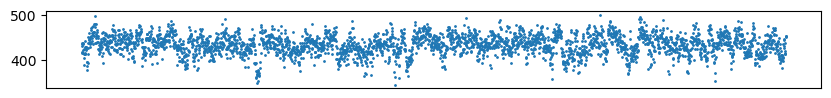

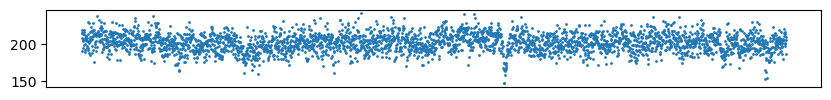

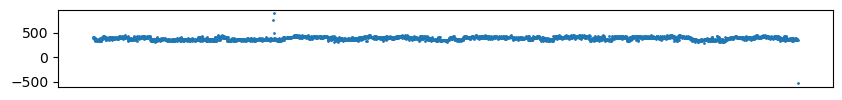

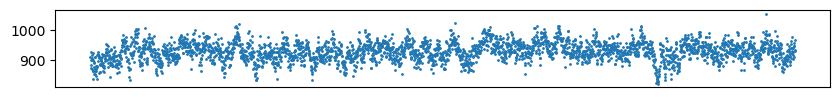

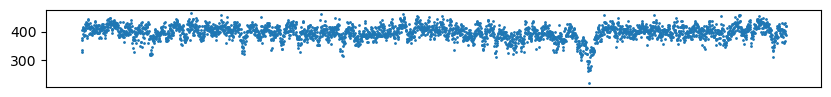

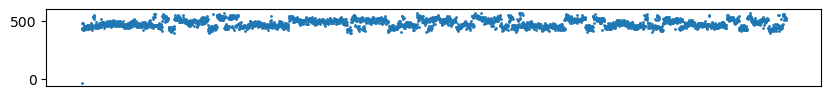

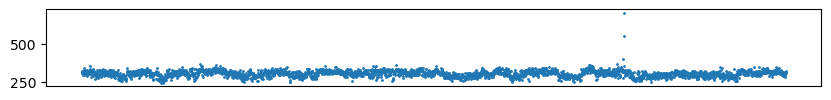

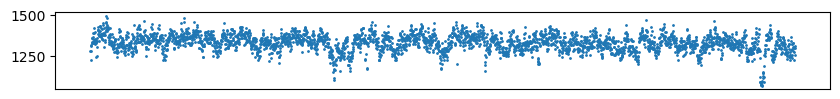

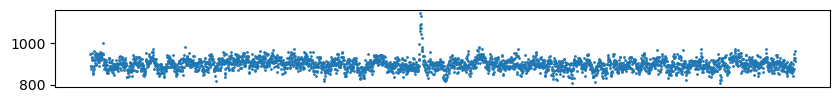

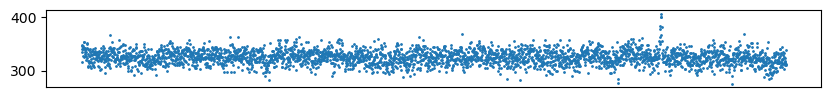

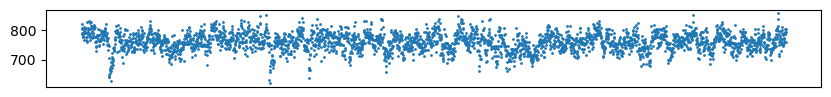

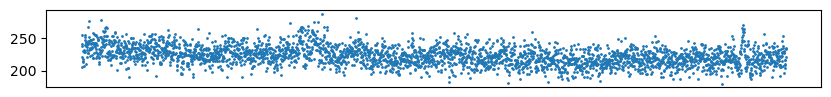

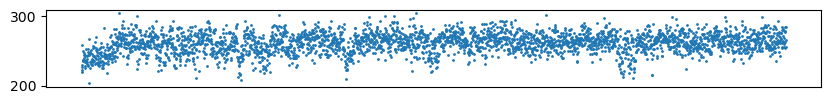

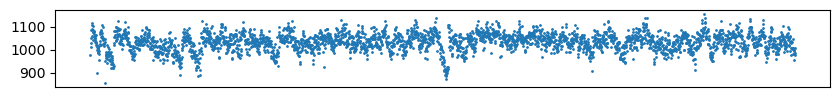

In [28]:
plt.rcParams["figure.figsize"] = (10, 1)

# final_df=concat2.sort_values('snr_local_brightening_filtered2', ascending=False).drop(index=droplist)[:20]
for index in final_df.index[:30].values:
    # print(concat.loc[index,'global_noise_over_average'])
    # plt.set_figsize((5,2))
    tot, maxols = rff.get_tot_csv(concat2, index)
    plt.plot(tot, '.', ms=2)
    # plt.title(str(final_df.loc[index, "real_type"])+", "+str(final_df.loc[index, "concat_index_copy"]))
    plt.xticks([])
    # plt.xlim(newbrightening.loc[index, 'central_point_brightening']-15, newbrightening.loc[index, 'central_point_brightening']+15)
    plt.show()

In [29]:
concat2['diff_brightening_local'] = concat2['snr_local_brightening_filtered2']-concat2['snr_local_brightening']

In [32]:
droplist=np.load('/home/3155/droplist_partial.npy')

In [62]:
concat2.iloc[0]

Unnamed: 0.4                                                                0
Unnamed: 0.3                                                                0
Unnamed: 0.2                                                                0
Unnamed: 0.1                                                                0
Unnamed: 0                                                                  0
filename                             ztf_20221020141806_000686_zi_c11_x_0017.
quad                                                                        4
type                                                                      pos
row_from_nn                                                             686.5
col_from_nn                                                             907.0
detection_size                                                              2
closest_x                                                               919.0
closest_y                                                       

In [57]:
df.index[:figrows].values

array([195365, 291022, 163685, 326045,  93680, 140710, 219077,  36179,
       130538,  50707, 103840, 124219,  17564, 272511,   8685, 106272,
       327334, 295009, 134872, 303828,  44164, 340401,  44168, 272322,
       306621, 265333,  86026, 163212,  90982,  83421])

In [67]:
def add_snr_filt_column(df):
    df['snr_local_filt2']=np.zeros(len(df))
    df['snr_global_filt2']=np.zeros(len(df))
    df['real_type_filt2'] = np.full(len(df), "unsure")
    for i, row in df.iterrows():
        if row['snr_local_brightening_filtered2']>row['snr_local_dimming_filtered2']:
            df.loc[i, 'snr_local_filt2']=row['snr_local_brightening_filtered2']
            df.loc[i, 'real_type_filt2']='pos'
        else:
            df.loc[i, 'snr_local_filt2']=row['snr_local_dimming']
            df.loc[i, 'real_type_filt2']='neg'
        if row['snr_global_brightening_filtered2']>row['snr_global_dimming_filtered2']:
            df.loc[i, 'snr_globa_filt2l']=row['snr_global_brightening_filtered2']
        else:
            df.loc[i, 'snr_global_filt2']=row['snr_global_dimming_filtered2']
    return df

In [ ]:
concat3

In [68]:
concat2 = add_snr_filt_column(concat2)

In [71]:
concat2['

Unnamed: 0.4               0
Unnamed: 0.3               0
Unnamed: 0.2               0
Unnamed: 0.1               0
Unnamed: 0                 0
                      ...   
snr_local_filt2     0.208855
snr_global_filt2         0.0
real_type_filt2          pos
snr_loca_filt2l     0.208855
snr_globa_filt2l    0.221599
Name: 0, Length: 63, dtype: object

In [72]:
concat2['concat_index_copy']=concat2.index.values

In [93]:
len(xes)

30

In [96]:
int(df.loc[index, 'central_point_brightening_filtere'])+15

11

In [95]:
tot[int(df.loc[index, 'central_point_brightening_filtere'])-15:int(df.loc[index, 'central_point_brightening_filtere'])+15]

Series([], Name: flux_hap_2, dtype: float64)

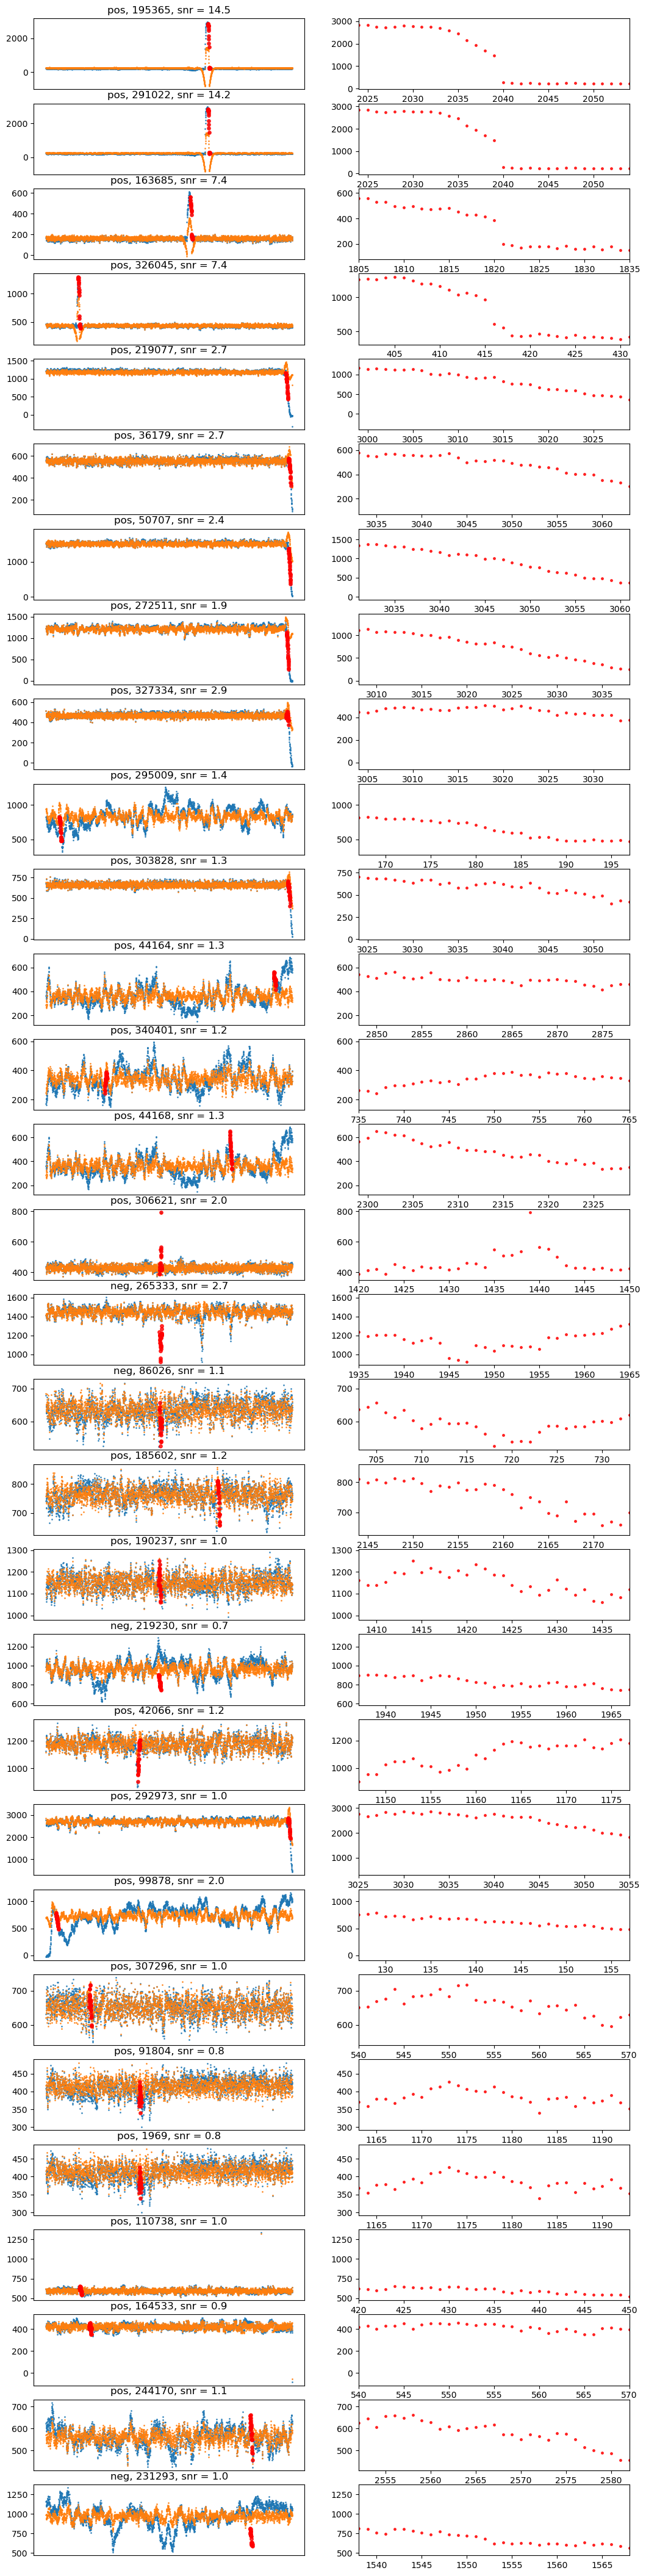

In [111]:

df = concat2.sort_values('diff_brightening_local', ascending=False).drop(index=droplist) #biggest filt>original
df = df[df['row_from_nn']>50]
figrows = 30
fig, ax = plt.subplots(figrows, 2, figsize=(7 * 1.8, figrows * 1.8))

for i, index in enumerate(df.index[:figrows].values):
    # print(index)
    tot, maxols = rff.get_tot_csv(concat2, index)
    ax[i,0].plot(tot, '.', ms=2, alpha=.8)
    tot_filt = rff.get_tot_csv_filtered_hap2(concat2, index)
    ax[i,0].plot(tot_filt, '.', ms=2, alpha=.8)
    ax[i,0].set_title(str(df.loc[index, "real_type_filt2"])+", "+str(df.loc[index, "concat_index_copy"])+", snr = "+f"{df.loc[index, 'snr_local_filt2']:.1f}")
    ax[i,0].set_xticks([])
    ax[i,1].plot(tot, '.', ms=5, alpha=.8, c='red')
    if str(df.loc[index, "real_type_filt2"])=='pos':
        xes = np.linspace(df.loc[index, 'central_point_brightening_filtere']-15,df.loc[index, 'central_point_brightening_filtere']+14,30)
        ax[i,1].set_xlim(df.loc[index, 'central_point_brightening_filtere']-15, df.loc[index, 'central_point_brightening_filtere']+15)
        ax[i,0].scatter(xes,tot[int(df.loc[index, 'central_point_brightening_filtere'])-15:int(df.loc[index, 'central_point_brightening_filtere'])+15],  s=15, alpha=.8, c='red', zorder=10)
    elif str(df.loc[index, "real_type_filt2"])=='neg':
        ax[i,1].set_xlim(df.loc[index, 'central_point_dimming_filtere']-15, df.loc[index, 'central_point_dimming_filtere']+15)
        ax[i,0].scatter(xes,tot[int(df.loc[index, 'central_point_dimming_filtere'])-15:int(df.loc[index, 'central_point_dimming_filtere'])+15],  s=15, alpha=.8, c='red', zorder=10)

    # plt.show()

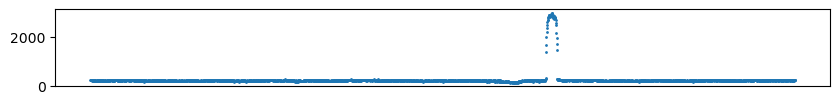

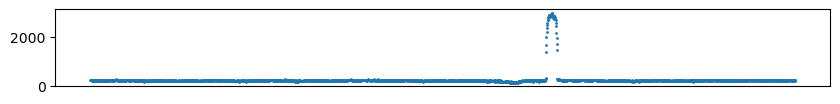

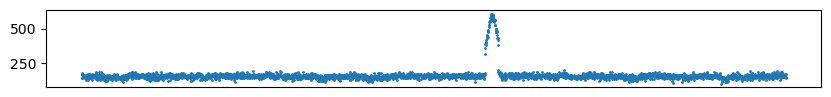

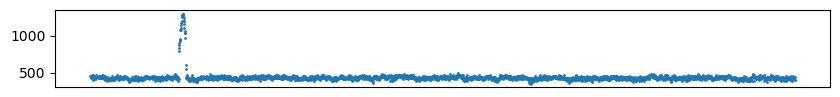

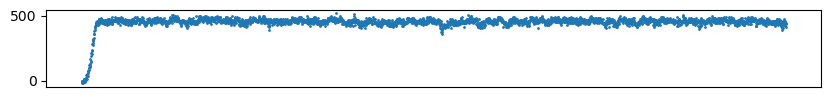

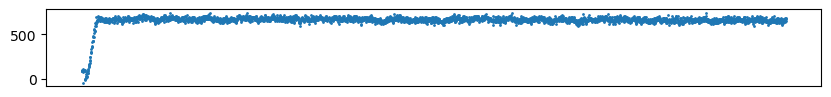

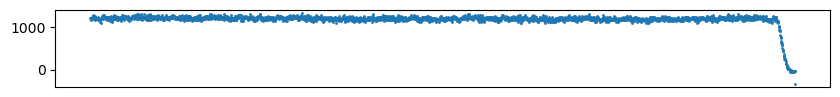

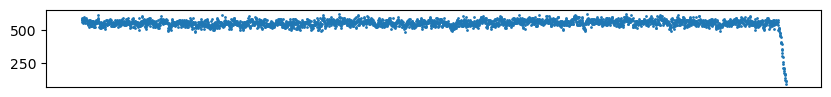

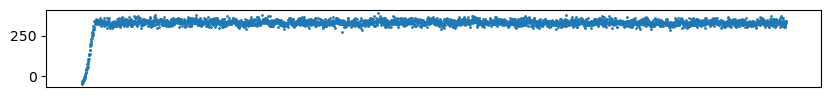

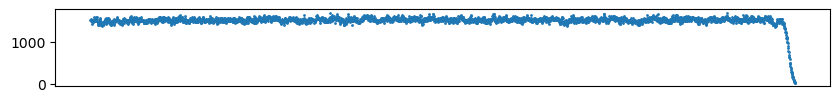

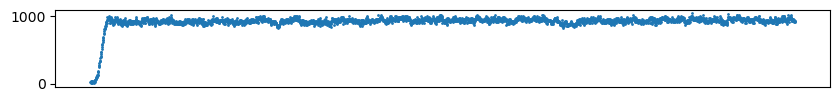

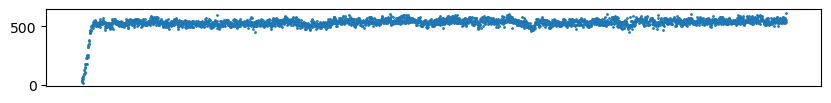

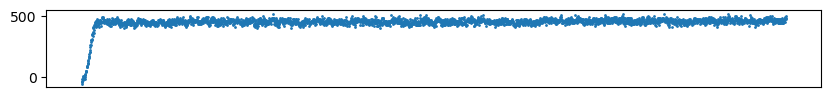

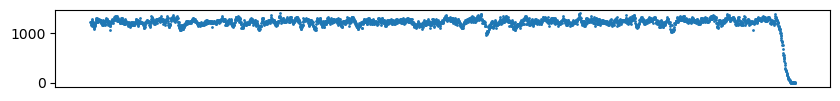

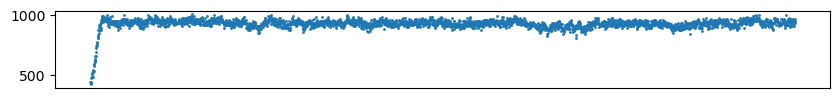

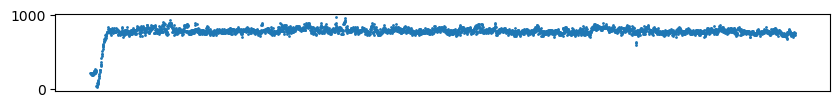

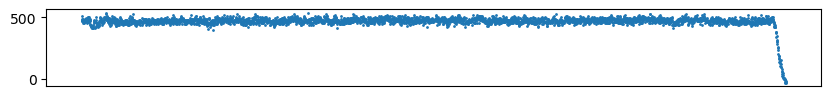

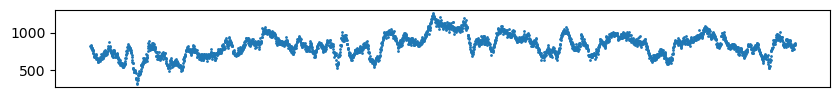

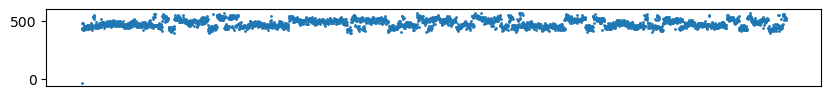

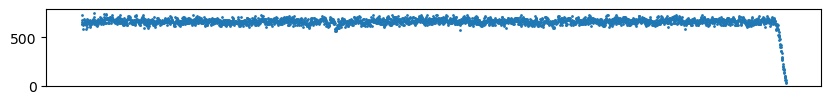

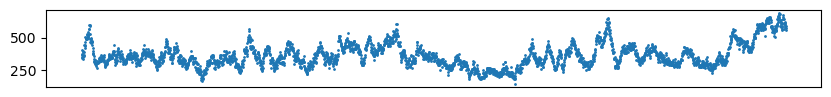

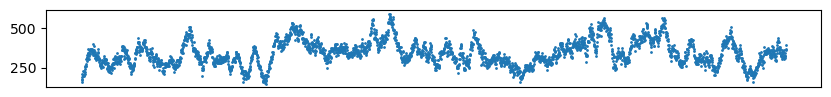

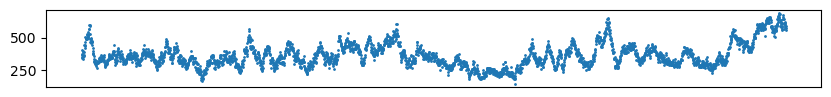

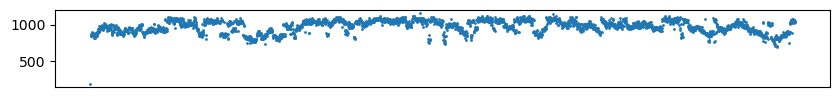

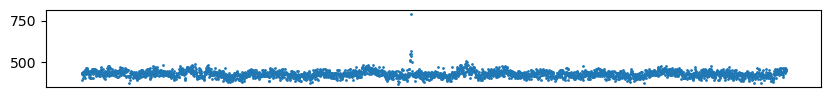

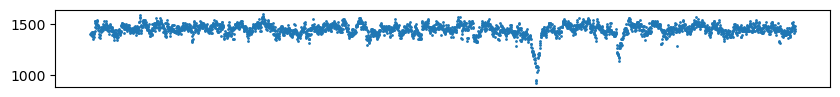

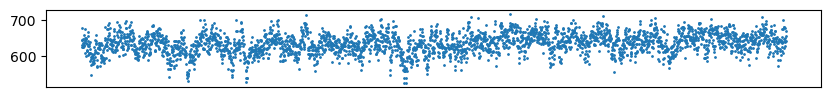

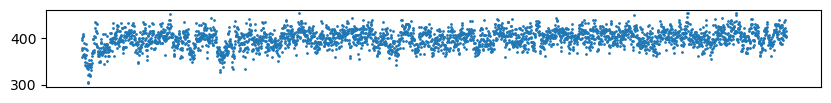

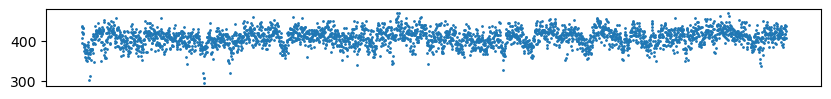

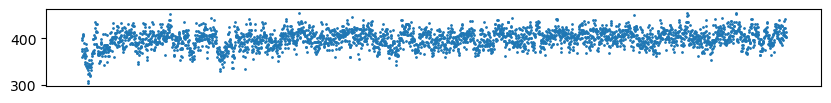

In [33]:
df = concat2.sort_values('diff_brightening_local', ascending=False).drop(index=droplist) #biggest filt>original
for index in df.index[:30].values:
    # print(concat.loc[index,'global_noise_over_average'])
    # plt.set_figsize((5,2))
    tot, maxols = rff.get_tot_csv(concat2, index)
    plt.plot(tot, '.', ms=2)
    # plt.title(str(final_df.loc[index, "real_type"])+", "+str(final_df.loc[index, "concat_index_copy"]))
    plt.xticks([])
    # plt.xlim(newbrightening.loc[index, 'central_point_brightening']-15, newbrightening.loc[index, 'central_point_brightening']+15)
    plt.show()

In [ ]:
#okay so that isn't in itself something that solves everything
# let's check o the ones that are very different from the original

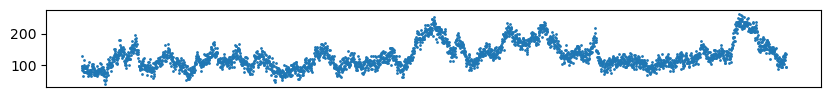

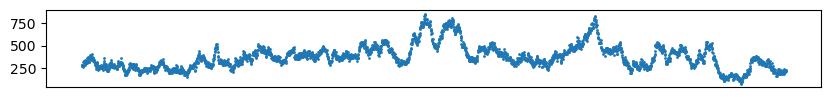

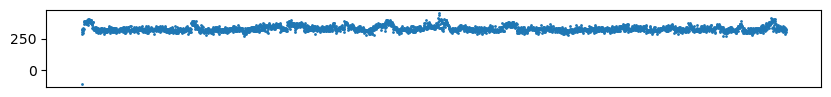

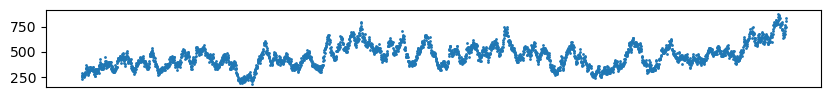

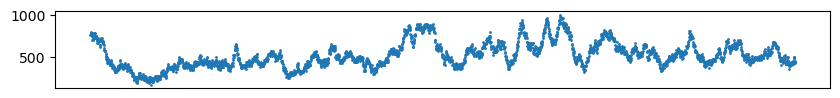

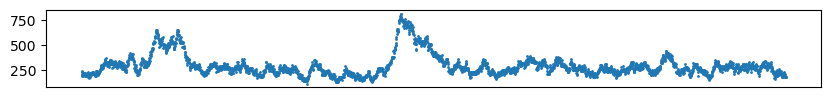

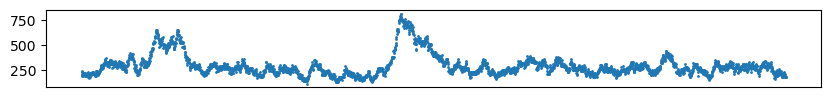

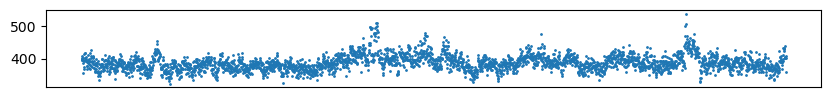

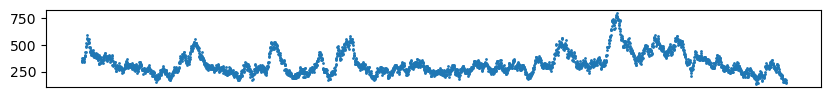

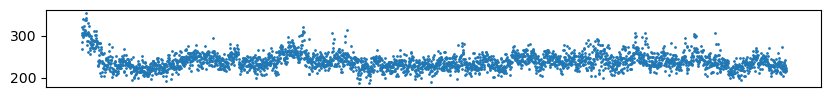

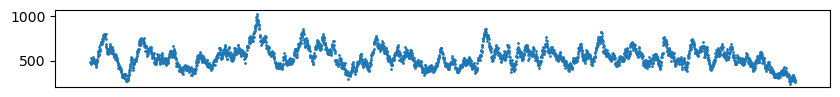

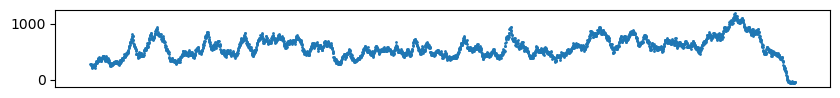

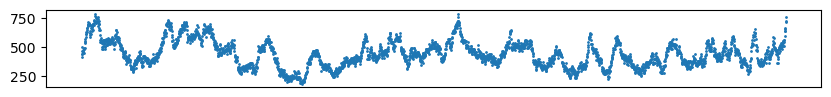

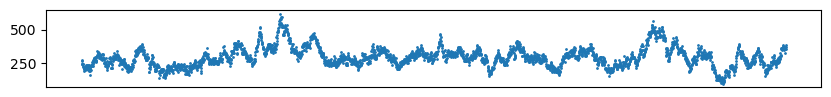

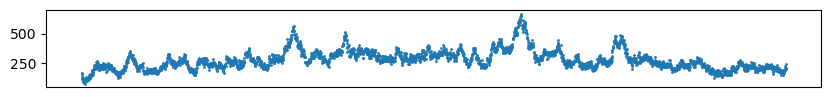

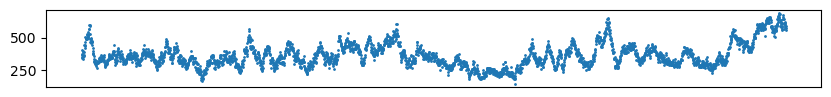

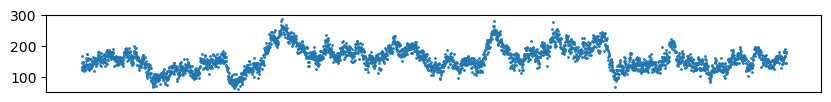

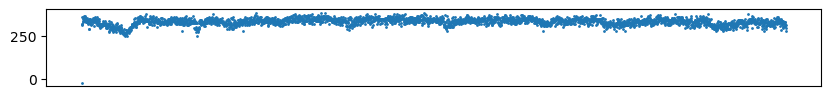

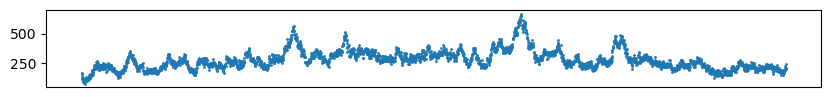

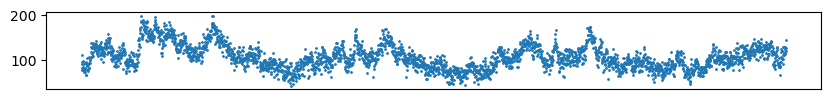

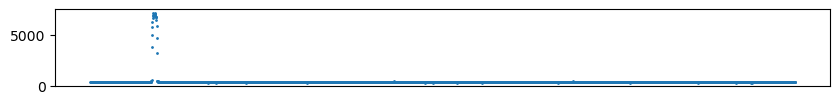

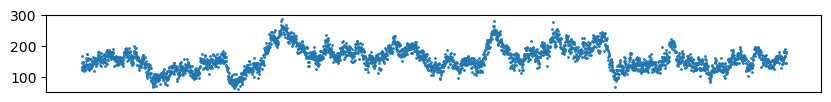

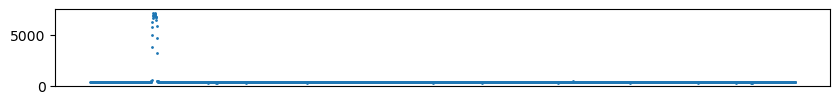

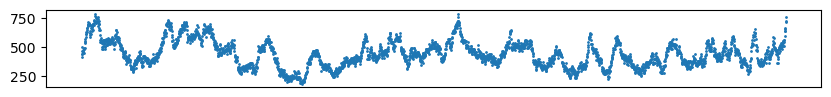

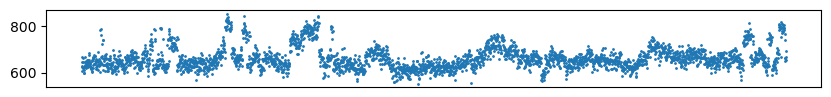

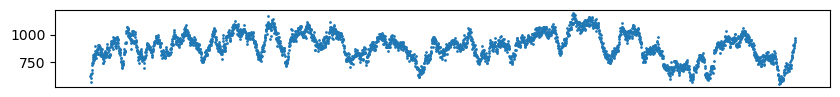

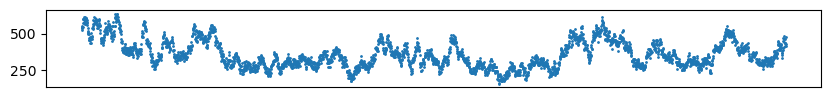

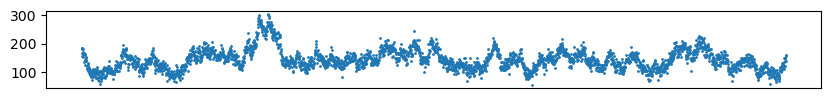

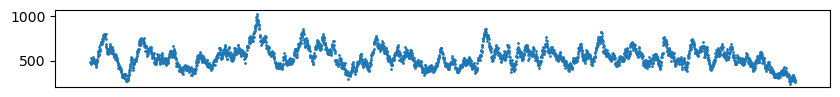

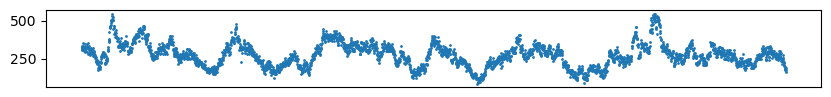

In [34]:
df = concat2.sort_values('diff_brightening_local', ascending=True).drop(index=droplist) #biggest original>filt
for index in df.index[:30].values:
    # print(concat.loc[index,'global_noise_over_average'])
    # plt.set_figsize((5,2))
    tot, maxols = rff.get_tot_csv(concat2, index)
    plt.plot(tot, '.', ms=2)
    # plt.title(str(final_df.loc[index, "real_type"])+", "+str(final_df.loc[index, "concat_index_copy"]))
    plt.xticks([])
    # plt.xlim(newbrightening.loc[index, 'central_point_brightening']-15, newbrightening.loc[index, 'central_point_brightening']+15)
    plt.show()